# Logistic model for third-down conversion

Team 2: Nathan Sabbara and Anthony Feaster II

The exploratory analysis is in `01_initial_eda.ipynb`. This notebook takes that sample and estimates a model for whether the third down converts. We compared three ways to write the probability and kept the logistic regression.

The outcome is `third_down_converted`. The predictors are yards to go, whether the play is a called run or a pass, and whether the first down is the goal line. A quarterback scramble is coded as a pass. In the raw file those plays are labeled as runs.

An AI assistant drafted the fitting and plotting code. We defined the sample, selected the three candidate models, and checked the fitted values against the output.


## From the exploratory analysis

The exploratory sample is regular-season third downs that are a pass or a run and that have a recorded conversion. That sample has 21,948 plays, and 39.69% converted. The rate is stable across seasons, between about 39% and 41%. It falls with distance: 63.38% at 1–2 yards, and 15.07% at 11 yards or more. Quarter and score differential change the rate very little. Inside the offense's own 20-yard line, the rate is about 31%.

We kept yards to go as the recorded distance. Placing 3rd-and-1 and 3rd-and-10 in one bin would average over plays that convert at very different rates, and the exploratory comparison of run and pass already shows runs converting more often at short distances and passes converting more often when more yards are required. Goal-to-go enters for a related reason. A 3rd-and-1 on the goal line converts less often than a 3rd-and-1 in the open field. Quarter and score stay out of the model, because those rates were nearly flat.

We also separated scrambles from called runs. When `qb_scramble` equals 1, the file still records `play_type` as a run. Those plays are dropbacks on which the quarterback left the pocket, so we coded them as passes. In the model below, a run is a called run.


In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from pathlib import Path

candidates = [Path("data/raw"), Path("../data/raw")]
data_dir = next(path for path in candidates if path.exists())

keep = [
    "season", "season_type", "down", "ydstogo", "play_type",
    "third_down_converted", "goal_to_go", "qb_scramble",
]
frames = []
for season in [2023, 2024, 2025, 2026]:
    path = data_dir / f"play_by_play_{season}.csv"
    frames.append(pd.read_csv(path, usecols=keep))
pbp = pd.concat(frames, ignore_index=True)

third = pbp[
    (pbp["season_type"] == "REG")
    & (pbp["down"] == 3)
    & (pbp["play_type"].isin(["pass", "run"]))
    & (pbp["third_down_converted"].notna())
    & (pbp["ydstogo"] >= 1)
    & (pbp["goal_to_go"].notna())
].copy()
third["yards"] = third["ydstogo"].astype(int)
third["converted"] = third["third_down_converted"].astype(int)
third["goal"] = (third["goal_to_go"] == 1).astype(int)

# Scrambles are passes. The file still labels them as runs.
n_scramble = int((third["qb_scramble"].fillna(0) == 1).sum())
n_file_runs = int((third["play_type"] == "run").sum())
third["play"] = np.where(third["qb_scramble"].fillna(0) == 1, "pass", third["play_type"])
third["play"] = pd.Categorical(third["play"], categories=["pass", "run"])

# 2026 only goes through Week 3, so the fit is the three finished seasons.
fit = third[third["season"].isin([2023, 2024, 2025])].copy()
holdout = third[third["season"] == 2026].copy()

print(f"2023-2025 plays: {len(fit):,}")
print(
    f"Scrambles moved to the pass: {n_scramble:,} "
    f"(out of {n_file_runs:,} plays the file called runs)"
)
print(fit.groupby("play", observed=True)["converted"].agg(["mean", "count"]))
print(f"2026 left out: {len(holdout):,} plays")


2023-2025 plays: 20,769
Scrambles moved to the pass: 1,096 (out of 5,493 plays the file called runs)
          mean  count
play                 
pass  0.361884  16602
run   0.532277   4167
2026 left out: 1,179 plays


## Three candidate models

A third down either converts or it does not, so each candidate has to return a probability. We fit all three with the same predictors. The comparison is the form of the model. $R = 1$ for a called run and $R = 0$ for a pass, including scrambles. $G = 1$ when the first down is the goal line.

1. **Linear model.** Least squares applied to the 0/1 outcome. The probability is a straight line:

$$
\pi = \beta_0 + \beta_1(\text{yards}) + \beta_2 R + \beta_3(\text{yards} \times R) + \beta_4 G.
$$

2. **Binomial model with an identity link.** The mean is the same straight line. The variance is $\pi(1-\pi)$, the variance of a binary outcome, rather than a constant normal variance.

3. **Logistic regression.** The line is written on the log-odds, which keeps the probability between 0 and 1:

$$
\log\frac{\pi}{1-\pi} = \beta_0 + \beta_1(\text{yards}) + \beta_2 R + \beta_3(\text{yards} \times R) + \beta_4 G.
$$


## Pros and cons

The linear model is the most direct to interpret. A coefficient is a change in the conversion probability, so one additional yard shifts the chance by a fixed amount. A binary outcome is not a normal measurement, and its variance is not constant. A straight line in the probability can also fall below 0 or rise above 1.

The identity-link binomial model uses a variance that matches a binary play, and a coefficient is still a difference in rate. The mean remains a straight line. The exploratory rates fall quickly at short distances and then level off, and one line cannot follow both parts of that pattern. Fitted values can also reach the boundary at 0 or 1.

Logistic regression keeps every probability between 0 and 1. The curve is steeper near a 50% chance and flatter once the chance is already small, which is the pattern in the exploratory rates. A coefficient is a change in the log-odds, with odds ratio $e^{\beta}$, so the probability is obtained by evaluating the curve at a chosen distance.

We did not rank the linear model against the logit by AIC. That criterion compares models that share a likelihood, and these two do not. The identity-link model and the logit share a binomial likelihood, but the identity-link fit did not return a usable AIC, because some fitted values reached the boundary. We compared the three fits by whether the probabilities stayed between 0 and 1, and by how close they came to the observed rates at 1 yard and at 20 yards.


In [2]:
formula = "converted ~ yards * C(play, Treatment(reference='pass')) + goal"
linear_model = smf.ols(formula, data=fit).fit()
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    identity_model = smf.glm(
        formula,
        data=fit,
        family=sm.families.Binomial(link=sm.families.links.Identity()),
    ).fit()
logit_model = smf.glm(formula, data=fit, family=sm.families.Binomial()).fit()


def fitted_chance(model, yards, play_name, goal_flag):
    """Fitted conversion probability at one distance, call, and goal-line flag."""
    row = pd.DataFrame({
        "yards": [yards],
        "play": pd.Categorical([play_name], categories=["pass", "run"]),
        "goal": [goal_flag],
    })
    return float(model.predict(row).iloc[0])


def outside_unit_interval(model, frame):
    """How many sample plays get a fitted chance below 0 or above 1."""
    fitted = model.predict(frame)
    return int(((fitted < 0) | (fitted > 1)).sum()), float(fitted.min()), float(fitted.max())


comparison_rows = []
for yards in [1, 10, 20]:
    for play_name in ["run", "pass"]:
        observed = fit[(fit["yards"] == yards) & (fit["play"] == play_name) & (fit["goal"] == 0)]
        comparison_rows.append({
            "yards": yards,
            "play": play_name,
            "n": len(observed),
            "observed": float(observed["converted"].mean()) if len(observed) else np.nan,
            "linear": fitted_chance(linear_model, yards, play_name, 0),
            "identity": fitted_chance(identity_model, yards, play_name, 0),
            "logit": fitted_chance(logit_model, yards, play_name, 0),
        })
comparison = pd.DataFrame(comparison_rows)
print("Open-field rate at 1, 10, and 20 yards, and what each model gives.")
display(comparison.round(3))

for name, model in [("linear", linear_model), ("identity", identity_model), ("logit", logit_model)]:
    n_outside, low, high = outside_unit_interval(model, fit)
    print(f"{name}: {n_outside:,} fitted values outside (0, 1), range {low:.3f} to {high:.3f}")

print(f"Linear model R-squared: {linear_model.rsquared:.3f}")
print(f"Logit AIC: {logit_model.aic:.1f}")
print(f"Identity-link AIC: {identity_model.aic}")


Open-field rate at 1, 10, and 20 yards, and what each model gives.


,yards,play,n,observed,linear,identity,logit
0,1,run,1715,0.741,0.660,0.610,0.709
1,1,pass,561,0.583,0.554,0.450,0.596
2,10,run,83,0.084,0.295,0.453,0.109
3,10,pass,1591,0.280,0.303,0.346,0.276
4,20,run,23,0.000,-0.111,0.279,0.004
5,20,pass,147,0.027,0.024,0.231,0.078


linear: 501 fitted values outside (0, 1), range -0.761 to 0.660
identity: 4 fitted values outside (0, 1), range -0.000 to 0.610
logit: 0 fitted values outside (0, 1), range 0.000 to 0.709
Linear model R-squared: 0.115
Logit AIC: 25055.0
Identity-link AIC: nan


/private/tmp/aai-venv/lib/python3.9/site-packages/statsmodels/genmod/families/family.py:1056: RuntimeWarning: invalid value encountered in log
  special.gammaln(n - y + 1) + y * np.log(mu / (1 - mu + 1e-20)) +


## Why we selected the logit

The linear model assigned a probability below 0 to 501 plays. Its highest fitted probability is 0.66, below the 0.74 observed for an open-field called run on 3rd-and-1. At 20 yards the called-run line is negative.

The identity-link model stays inside 0 and 1 for nearly every play. The straight line still misses the shape of the rates. At 1 yard it gives 0.61 for a called run and 0.45 for a pass, against observed rates of 0.74 and 0.58. At 20 yards it remains near 0.23 to 0.28, against observed rates of 0.00 and 0.03.

The logit follows that decline. At 1 yard the fitted probabilities are 0.71 and 0.60. At 20 yards they are 0.00 and 0.08. Every fitted probability on the estimation sample lies between 0 and 1. This is the model we interpret below.


## The estimated model

$$
\log\frac{\pi}{1-\pi}
  = \beta_0 + \beta_1(\text{yards}) + \beta_2 R + \beta_3(\text{yards} \times R) + \beta_4 G.
$$

We estimated the coefficients by maximum likelihood on the 20,769 regular-season plays from 2023, 2024, and 2025. The 2026 file contains only Weeks 1 through 3, so we held those plays out. Including a partial season would shift the coefficients toward a few weeks of football. $R = 1$ only for a called run. Scrambles are coded as passes, so $R = 0$ for those plays.


In [3]:
print(logit_model.summary())

confidence = logit_model.conf_int()
confidence.columns = ["ci_low", "ci_high"]
odds = pd.DataFrame({
    "coefficient": logit_model.params,
    "odds_ratio": np.exp(logit_model.params),
    "or_low": np.exp(confidence["ci_low"]),
    "or_high": np.exp(confidence["ci_high"]),
    "p_value": logit_model.pvalues,
})
print()
display(odds.round(4))

run_name = "C(play, Treatment(reference='pass'))[T.run]"
slope_name = "yards:C(play, Treatment(reference='pass'))[T.run]"
beta0 = float(logit_model.params["Intercept"])
beta_yards = float(logit_model.params["yards"])
beta_run = float(logit_model.params[run_name])
beta_interaction = float(logit_model.params[slope_name])
crossover = -beta_run / beta_interaction
print(f"Pass line: {beta0:.3f} + ({beta_yards:.3f}) * yards")
print(f"Called-run intercept: {beta0 + beta_run:.3f}")
print(f"Called-run slope: {beta_yards + beta_interaction:.3f}")
print(f"The lines cross at {crossover:.1f} yards when it isn't goal-to-go.")
print(f"Goal-to-go multiplies the odds by {np.exp(logit_model.params['goal']):.3f}.")


                 Generalized Linear Model Regression Results                  
Dep. Variable:              converted   No. Observations:                20769
Model:                            GLM   Df Residuals:                    20764
Model Family:                Binomial   Df Model:                            4
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -12522.
Date:                Fri, 16 Oct 2026   Deviance:                       25045.
Time:                        18:31:34   Pearson chi2:                 2.11e+04
No. Iterations:                     6   Pseudo R-squ. (CS):             0.1279
Covariance Type:            nonrobust                                         
                                                        coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------

,coefficient,odds_ratio,or_low,or_high,p_value
Intercept,0.5384,1.7132,1.6008,1.8335,0.0
"C(play, Treatment(reference='pass'))[T.run]",0.6831,1.9800,1.7532,2.2362,0.0
yards,-0.1504,0.8604,0.8529,0.8679,0.0
"yards:C(play, Treatment(reference='pass'))[T.run]",-0.1823,0.8333,0.8075,0.8600,0.0
goal,-0.4548,0.6346,0.5567,0.7233,0.0


Pass line: 0.538 + (-0.150) * yards
Called-run intercept: 1.222
Called-run slope: -0.333
The lines cross at 3.7 yards when it isn't goal-to-go.
Goal-to-go multiplies the odds by 0.635.


## Interpreting the coefficients

For a pass, the fitted line is

$$
\log\frac{\pi}{1-\pi} = 0.538 - 0.150 \times (\text{yards to go}).
$$

Each additional yard multiplies a pass's odds of converting by 0.86. The called-run line has intercept 1.222 and slope $-0.333$, so it begins higher and declines faster. The two lines cross at 3.7 yards when the play is not goal-to-go. At shorter distances the called run has the higher fitted probability. At longer distances the pass does.

On 3rd-and-10, substituting 10 yards for a pass gives $0.538 - 0.150 \times 10 = -0.962$, and

$$
\pi = \frac{e^{-0.962}}{1 + e^{-0.962}} = 0.28.
$$

For a called run, $1.222 - 0.333 \times 10 = -2.108$, which is a probability of 0.11. The same substitution at 1 yard gives 0.60 for a pass and 0.71 for a called run.

Goal-to-go leaves the slopes unchanged and multiplies the odds by 0.635. A 3rd-and-1 called run falls from 0.71 in the open field to 0.61 on the goal line, and a pass falls from 0.60 to 0.48.

The table evaluates that calculation at distances that arise often in a game. The figure shows the open-field rates with the fitted curves. Marker area is proportional to the number of plays at that distance, so a long-yardage run based on a few dozen plays is drawn lighter than 3rd-and-1.


play                     pass    run
situation  yards_to_go              
goal line  1            0.483  0.607
           2            0.446  0.525
           3            0.409  0.442
           4            0.373  0.363
           6            0.306  0.226
           8            0.246  0.131
           10           0.195  0.072
           15           0.102  0.014
open field 1            0.596  0.709
           2            0.559  0.636
           3            0.522  0.556
           4            0.484  0.473
           6            0.410  0.315
           8            0.340  0.192
           10           0.276  0.109
           15           0.152  0.023

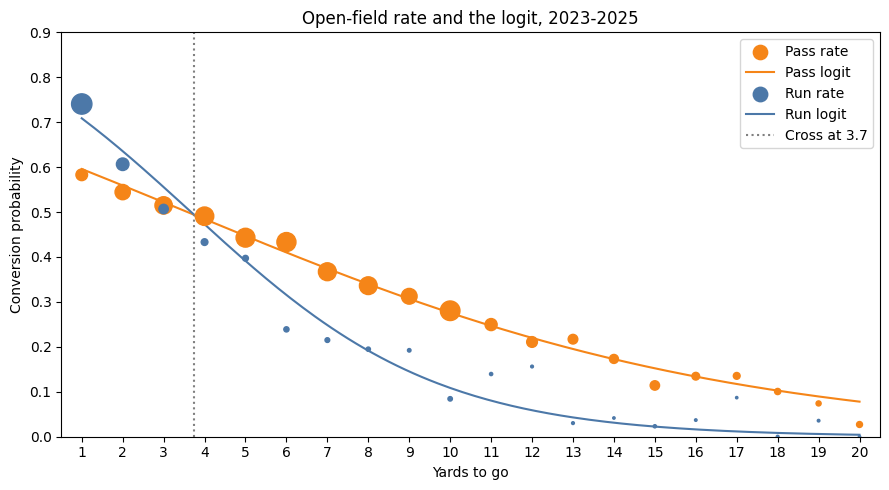

2026 left out of the fit: actual 0.412, model says 0.393, n = 1,179


In [4]:
use_rows = []
for yards in [1, 2, 3, 4, 6, 8, 10, 15]:
    for play_name in ["run", "pass"]:
        for goal_flag, situation in [(0, "open field"), (1, "goal line")]:
            use_rows.append([
                yards,
                situation,
                play_name,
                fitted_chance(logit_model, yards, play_name, goal_flag),
            ])
use_table = pd.DataFrame(use_rows, columns=["yards_to_go", "situation", "play", "fitted_chance"])
display(
    use_table.pivot_table(
        index=["situation", "yards_to_go"],
        columns="play",
        values="fitted_chance",
    ).round(3)
)

open_field = fit[fit["goal"] == 0]
observed_rows = []
for (yards, play_name), group in open_field.groupby(["yards", "play"], observed=True):
    observed_rows.append({
        "yards": int(yards),
        "play": play_name,
        "n": len(group),
        "rate": float(group["converted"].mean()),
    })
observed = pd.DataFrame(observed_rows)
observed = observed[observed["yards"] <= 20]

yard_grid = np.linspace(1, 20, 191)
colors = {"run": "#4c78a8", "pass": "#f58518"}
plt.figure(figsize=(9, 5))
for play_name, group in observed.groupby("play"):
    plt.scatter(
        group["yards"],
        group["rate"],
        s=group["n"] / 8,
        color=colors[play_name],
        label=f"{play_name.capitalize()} rate",
        zorder=3,
    )
    curve = [fitted_chance(logit_model, float(yard), play_name, 0) for yard in yard_grid]
    plt.plot(yard_grid, curve, color=colors[play_name], label=f"{play_name.capitalize()} logit")
plt.axvline(crossover, color="gray", linestyle=":", label=f"Cross at {crossover:.1f}")
plt.xticks(range(1, 21, 1))
plt.xlim(0.5, 20.5)
plt.ylim(0, 0.9)
plt.xlabel("Yards to go")
plt.ylabel("Conversion probability")
plt.title("Open-field rate and the logit, 2023-2025")
plt.legend()
plt.tight_layout()
plt.show()

holdout = holdout.copy()
holdout["predicted"] = logit_model.predict(holdout)
print(
    f"2026 left out of the fit: actual {holdout['converted'].mean():.3f}, "
    f"model says {holdout['predicted'].mean():.3f}, n = {len(holdout):,}"
)


In the table, the pass column includes scrambles and the run column is limited to called runs.

In the open field, a called run on 3rd-and-1 has a fitted probability of about 0.71, and a pass about 0.60. At 3 yards the called run remains slightly higher, 0.56 against 0.52. At 4 yards the pass is higher, 0.48 against 0.47. On 3rd-and-10 the pass is 0.28 and the called run is 0.11. On the goal line, each of those probabilities is obtained by multiplying the corresponding odds by 0.635.

For a decision about converting the down, we read both calls at the given distance and, on the goal line, apply that factor. The called run has the higher probability inside about 4 yards, and the pass has the higher probability beyond that. The comparison concerns the third down itself. Quarter and score did not meaningfully change the exploratory rates, and the model does not incorporate the clock or the rest of the drive.

The 1,179 plays from Weeks 1 through 3 of 2026 were held out of estimation. The model predicts a conversion rate of 0.393 on those plays, and the observed rate is 0.412. The two are close for a season the coefficients have not seen. Three weeks remains too small a sample on which to re-estimate the line.

The offense selected these plays, so the difference between run and pass describes the calls that were made. Requiring the other call is a separate question, and this sample does not answer it. Plays from the same game are also dependent, while the reported standard errors treat them as independent. Those standard errors are likely somewhat too small.
